# Week 7a.2: Multi-Agent Collaboration

**The running example: a deep research agent over arXiv**

A research question over the literature does not always have one answer in one place. It typically involves several parts, each part has its own papers, and the papers have to be read before they can be cited. One agent can do that, slowly, in one context that fills up as it goes.

<img src="figures/team.png" width="700">

Two patterns with the same tools:

- **One agent** searches, reads, searches again, all in one context. 
- **A team** has a lead that writes sub-questions, workers that each take one in their own context and in parallel, and the lead again to put the findings together.

In [1]:
from dotenv import load_dotenv
import os

load_dotenv()
assert os.getenv("GOOGLE_API_KEY"), "No GOOGLE_API_KEY found."
print("API key loaded")

API key loaded


## 0. Model Setup

Execute one of the following to define the model.

In [2]:
from langchain_ollama import ChatOllama

model = ChatOllama(model="qwen3.5:9b", reasoning=False)

In [ ]:
from langchain.chat_models import init_chat_model

model = init_chat_model(model="gpt-4.1-mini")

In [ ]:
from langchain_google_genai import ChatGoogleGenerativeAI

model = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

In [ ]:
from langchain_nvidia_ai_endpoints import ChatNVIDIA
model = ChatNVIDIA(model="nvidia/nemotron-3.5-super-vl-120b-a12b")
#model = ChatNVIDIA(model="nvidia/nemotron-3.5-lightning-30b-a3b")

## 1. The tools

Two tools in `research_tools.py`:

- `search_papers` takes a query and returns up to eight papers, each with its id in brackets. 
- `get_paper` takes one of a paper id and returns the full record. 


By default the papers come from `papers.json`, which contains the records for 244 papers fetched from arXiv around five research questions. Rate limits make it infeasible to retrieve the papers during class.

If you want to do a live search outside of the classroom, you should set `PAPER_SOURCE=live` in `.env` and the same two tools go to arXiv itself, or to Semantic Scholar if you have put an `S2_API_KEY` there.

In [3]:
import research_tools as rt

papers = rt.cache()["papers"]
print(f"{len(papers)} papers in the cache\n")

example = papers["2503.13657"]
for key, value in example.items():
    print(f"  {key:16} {str(value)[:70]}")

244 papers in the cache

  id               2503.13657
  title            Why Do Multi-Agent LLM Systems Fail?
  abstract         Despite enthusiasm for Multi-Agent LLM Systems (MAS), their performanc
  authors          ['Mert Cemri', 'Melissa Z. Pan', 'Shuyi Yang', 'Lakshya A. Agrawal', '
  year             2025
  published        2025-03-17
  categories       ['cs.AI']
  url              http://arxiv.org/abs/2503.13657v3
  citation_count   None
  source           arxiv


A search over the file is a real search, not a lookup. It ranks the cached papers by word overlap with the query, so a well-aimed query finds the paper and a vague one finds neighbors.

In [4]:
print(rt.search_papers("taxonomy of failure modes in multi-agent LLM systems", limit=4))

[2503.13657] Why Do Multi-Agent LLM Systems Fail? (2025). Mert Cemri, Melissa Z. Pan, Shuyi Yang et al..
    Despite enthusiasm for Multi-Agent LLM Systems (MAS), their performance gains on popular benchmarks are often minimal. This gap highlights a critical need for a principled understanding of why MAS fail. Addressing this q...
[2601.00360] Mapping Human Anti-collusion Mechanisms to Multi-agent AI Systems (2026). Jamiu Idowu, Ahmed Almasoud, Ayman Alfahid.
    As multi-agent AI systems become increasingly autonomous, evidence shows they can develop collusive strategies similar to those long observed in human markets and institutions. While human domains have accumulated centur...
[2308.08155] AutoGen: Enabling Next-Gen LLM Applications via Multi-Agent Conversation (2023). Qingyun Wu, Gagan Bansal, Jieyu Zhang et al..
    AutoGen is an open-source framework that allows developers to build LLM applications via multiple agents that can converse with each other to accomplish tasks. Auto

In [5]:
print(rt.get_paper("2503.13657")[:700])

[2503.13657] Why Do Multi-Agent LLM Systems Fail? (2025)
Mert Cemri, Melissa Z. Pan, Shuyi Yang, Lakshya A. Agrawal, Bhavya Chopra, Rishabh Tiwari, Kurt Keutzer, Aditya Parameswaran, Dan Klein, Kannan Ramchandran, Matei Zaharia, Joseph E. Gonzalez, Ion Stoica
http://arxiv.org/abs/2503.13657v3

Despite enthusiasm for Multi-Agent LLM Systems (MAS), their performance gains on popular benchmarks are often minimal. This gap highlights a critical need for a principled understanding of why MAS fail. Addressing this question requires systematic identification and analysis of failure patterns. We introduce MAST-Data, a comprehensive dataset of 1600+ annotated traces collected across 7 popular MAS fra


### Sample questions

Five research questions come with the file, each labeled with the papers an answer should cite.

In [6]:
for question, spec in rt.questions().items():
    print(question)
    for g in spec["gold"]:
        print(f"    [{g}] {papers[g]['title'][:70]}")
    print()

Why do multi-agent LLM systems fail, and what has been proposed to make them more reliable?
    [2503.13657] Why Do Multi-Agent LLM Systems Fail?
    [2308.08155] AutoGen: Enabling Next-Gen LLM Applications via Multi-Agent Conversati
    [2308.00352] MetaGPT: Meta Programming for A Multi-Agent Collaborative Framework
    [2303.17760] CAMEL: Communicative Agents for "Mind" Exploration of Large Language M

How can an LLM agent decide when to retrieve, and check whether what it retrieved is enough?
    [2310.11511] Self-RAG: Learning to Retrieve, Generate, and Critique through Self-Re
    [2401.15884] Corrective Retrieval Augmented Generation
    [2403.14403] Adaptive-RAG: Learning to Adapt Retrieval-Augmented Large Language Mod
    [2005.11401] Retrieval-Augmented Generation for Knowledge-Intensive NLP Tasks

What methods let an LLM agent reflect on and correct its own mistakes?
    [2303.11366] Reflexion: Language Agents with Verbal Reinforcement Learning
    [2303.17651] Self-Refine: I

## 2. Orchestrator and workers

<img src="figures/team.png" width="700">

An **orchestrator** reads the question and writes sub-questions. Each sub-question goes to a **worker**, which runs the assistant-tools loop from Week 4 with a narrower prompt and a fresh context every time it runs. 
- The delegation of tasks to workers by the orchestrator is known as **fan-out**

The workers run in **parallel**. Each returns a short finding, not its transcript. The orchestrator reads the findings and writes the report.
- The combination of the outputs of parallel operations into a single node is known as **fan-in**

In LangGraph this is a `map-reduce`: 
- a node that fans out with `Send`, one worker run per sub-question, and 
- a node that collects what they returned

In [8]:
import operator
from typing import Annotated, TypedDict
from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send


class ResearchState(TypedDict):
    question: str
    sub_questions: list
    findings: Annotated[list, operator.add]     # one entry per worker, appended
    tokens: Annotated[int, operator.add]        # every node adds what it spent
    report: str


class WorkerState(TypedDict):
    sub_question: str

NOTE:

`findings` uses a reducer so that sub-agents can all write to the same context


### The Orchestrator
The orchestrator will serve as the lead and break down a research question into multiple questions for better coverage.

In [9]:
class Plan(BaseModel):
    """The parts of a research question that need their own search."""
    sub_questions: list[str] = Field(
        description="Three sub-questions. Each covers a different part of the "
                    "question and is specific enough to search for on its own.")


PLAN_PROMPT = """A research question: {question}

Split it into three sub-questions that together cover it and do not overlap.
Every sub-question must stay on the question's own subject and reuse its key
terms, so that a literature search for the sub-question finds papers about
this question and not about a neighboring topic. Each sub-question must be
a standalone question without referring to other questions.

Cover: the main systems or methods that have been proposed, the problems or failures that have been
reported, and what has been measured or compared."""

planner = model.with_structured_output(Plan)


In [10]:
question = "Why do multi-agent LLM systems fail"
planner.invoke(PLAN_PROMPT.format(question=question))

Plan(sub_questions=['What multi-agent architecture patterns and communication protocols are predominantly adopted in current Large Language Model (LLM) systems?', 'Which specific failure modes and degradation behaviors have been observed across different types of multi-agent LLM systems during collaborative tasks?', 'What quantitative metrics and comparative benchmarks are used to evaluate the robustness, efficiency, and success rates of multi-agent LLM systems?'])

In [11]:
def plan(state: ResearchState) -> dict:
    out = planner.invoke(PLAN_PROMPT.format(question=state["question"]))
    return {"sub_questions": out.sub_questions}

### The worker

A worker is a simple ReAct agent, consisting of an `assistant` node with the two paper tools bound

Need to define the worker agent template as a function, because every worker will be spawned at runtime with its own prompt and its own fresh context.
- It's common to simply use `create_agent` for simple ReAct agents used in multi-agent systems

In [12]:
from langchain.messages import HumanMessage, SystemMessage
from langgraph.graph import MessagesState
from langgraph.prebuilt import ToolNode, tools_condition
from IPython.display import Image, display
import time

QUESTION = list(rt.questions())[0]
TOOLS = [rt.search_papers, rt.get_paper]


def build_agent(system_prompt):
    model_with_tools = model.bind_tools(TOOLS)
    sys_msg = SystemMessage(content=system_prompt)

    def assistant(state: MessagesState) -> dict:
        messages = model_with_tools.invoke([sys_msg] + state["messages"])
        return {"messages": [messages]}

    g = StateGraph(MessagesState)
    g.add_node("assistant", assistant)
    g.add_node("tools", ToolNode(TOOLS))
    g.add_edge(START, "assistant")
    g.add_conditional_edges("assistant", tools_condition)
    g.add_edge("tools", "assistant")
    return g.compile()

### Two helpers 
- One adds up the tokens the model reported 
- One lists the tool calls it made in order

In [13]:
def tokens_of(messages):
    """Total tokens the model reported across a run."""
    return sum((m.usage_metadata or {}).get("total_tokens", 0)
               for m in messages if getattr(m, "usage_metadata", None))


def tool_calls_of(messages):
    """The tool calls in a run, in order, as (tool, first argument)."""
    calls = []
    for m in messages:
        for call in getattr(m, "tool_calls", None) or []:
            first = next(iter(call["args"].values()), "")
            calls.append((call["name"], str(first)[:60]))
    return calls


In [14]:
WORKER_PROMPT = """You are a research assistant working on one sub-question of a
larger question. Start with a search that uses the sub-question's own words.
Read the 2-4 papers that matter with get_paper, preferring the papers
that introduced a system or method over papers that only apply or extend it.
Write a finding of at most 150 words: what those papers say about the
sub-question, with each claim followed by the paper id in brackets like
[2503.13657]. Cite only papers you have read."""

worker = build_agent(WORKER_PROMPT)        # the same loop, one job, a fresh context per run


In [15]:
sub_question = [HumanMessage(content=QUESTION)]
result = worker.invoke({"messages": sub_question})
result

{'messages': [HumanMessage(content='Why do multi-agent LLM systems fail, and what has been proposed to make them more reliable?', additional_kwargs={}, response_metadata={}, id='ea85f0a1-3955-414c-b508-030df898b8b1'),
  AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'qwen3.5:9b', 'created_at': '2026-10-20T20:42:21.042822Z', 'done': True, 'done_reason': 'stop', 'total_duration': 5782252541, 'load_duration': 4200708, 'prompt_eval_count': 531, 'prompt_eval_duration': 2945549000, 'eval_count': 45, 'eval_duration': 2810815000, 'logprobs': None, 'model_name': 'qwen3.5:9b', 'model_provider': 'ollama'}, id='lc_run--01a15b0c-e959-7460-b5c9-58ea44a843cf-0', tool_calls=[{'name': 'search_papers', 'args': {'query': 'multi-agent LLM systems failure reliability improvements', 'limit': 4}, 'id': 'c9dc3e3a-fd8c-4077-9db8-be74773a98e4', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 531, 'output_tokens': 45, 'total_tokens': 576}),
  ToolMessage(con

In [16]:
def research(state: WorkerState) -> dict:
    #TODO
    sub_question = [HumanMessage(content=state["sub_question"])]
    result = worker.invoke({"messages": sub_question})
    messages = result["messages"]
    return {"findings": [(state["sub_question"], messages[-1].text)],
            "tokens": tokens_of(messages)}

IMPORTANT NOTE:

`research` takes a `WorkerState`, not the `ResearchState`. 
- Each worker sees one sub-question, so the entire `ResearchState` isn't needed.
- This is known as **context isolation**



### Dynamic Fan-Out
Involves spawning nodes at runtime
- Send API is LangGraph’s mechanism for dynamic fan-out

`Send("node", payload)`
- node: the name of the node to run
- payload: the input that a spawned node receives

`Send("research", {"sub_question": q})`
- spawns a copy of the `research` node
- passes in q into the `sub_question` field of WorkerState



In [17]:
def fan_out(state: ResearchState):
    # fan out for each question in sub_questions
    return [Send("research", {"sub_question": q}) for q in state["sub_questions"]]

The fan-out is a conditional edge that returns one `Send` per sub-question. Each `Send` starts the `research` node with its own input, and LangGraph runs them concurrently.

```python

graph.add_conditional_edges("plan", fan_out, ["research"])
```

- `plan`: the fan-out starts after this node runs
- `fan_out`: the fan-out method that'll spawn the sub-agent nodes
- `["research"]`:  The list of target nodes


### Fan-in: Synthesis
The orchestrator combines the outputs from the worker nodes and synthesizes them


In [18]:
SYNTH_PROMPT = """Question: {question}

Findings from three researchers, each on one part of the question:

{findings}

Write the report: what is known, organized by the parts of the question, with
every claim followed by the paper id in brackets as the findings give it. Keep
every paper the findings cite; do not drop a citation when you condense, and
do not add papers the findings did not cite."""


def synthesize(state: ResearchState) -> dict:
    findings = "\n\n".join(f"Sub-question: {q}\n{f}" for q, f in state["findings"])
    out = model.invoke(SYNTH_PROMPT.format(question=state["question"], findings=findings))
    return {"report": out.text, "tokens": tokens_of([out])}

## 3. The Graph

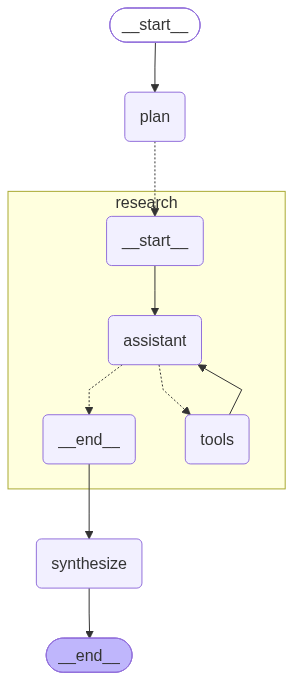

In [27]:
graph = StateGraph(ResearchState)
graph.add_node("plan", plan)
graph.add_node("research", research)
graph.add_node("synthesize", synthesize)

graph.add_edge(START, "plan")
#TODO add fan-out
graph.add_conditional_edges("plan", fan_out, ["research"])
graph.add_edge("research", "synthesize")
graph.add_edge("synthesize", END)

team = graph.compile()
display(Image(team.get_graph(xray=True).draw_mermaid_png()))

NOTE:

Three workers each making two or three model calls at the same moment, plus the plan and the synthesis, is a dozen calls in a short amount of time, and the Gemini free tier allows 15 calls/minute.

In [22]:
def run_team(question):
    start = time.time()
    result = team.invoke({"question": question})
    return {"report": result["report"], "sub_questions": result["sub_questions"],
            "findings": result["findings"], "tokens": result["tokens"],
            "seconds": time.time() - start}

In [23]:
multi = run_team(QUESTION)

print("sub-questions:")
for q in multi["sub_questions"]:
    print("  -", q)
print()
print(multi["report"])

sub-questions:
  - What are the specific failure modes, reliability issues, and limitations reported in multi-agent Large Language Model (LLM) systems?
  - Which architectural designs, coordination mechanisms, and regulatory protocols have been proposed to enhance the reliability of multi-agent LLM systems?
  - What metrics, benchmarks, and comparative studies have been used to evaluate performance differences between unreliable baseline systems and proposed improvements in multi-agent LLMs?

# Report on Multi-Agent LLM Systems: Failures and Reliability Improvements

### 1. Known Failure Modes, Reliability Issues, and Limitations
Multi-agent Large Language Model (LLM) systems exhibit distinct failure modes categorized into system design issues, inter-agent misalignment, and task verification problems. A comprehensive study utilizing the MAST-Data dataset, which comprises over 1600 annotated traces across seven frameworks, identified a taxonomy of 14 unique failure modes [2503.13657].
*

In [24]:
multi["findings"]

[('What are the specific failure modes, reliability issues, and limitations reported in multi-agent Large Language Model (LLM) systems?',
  'Multi-agent LLM systems face several specific failure modes documented in recent research [2503.13657]. A comprehensive study using MAST-Data, a dataset of 1600+ annotated traces across 7 frameworks, identified a taxonomy (MAST) with 14 unique failure modes clustered into three categories: system design issues, inter-agent misalignment, and task verification problems [2503.13657]. System design failures often include inefficient orchestration or poor role definition in agent teams [2503.13657]. Inter-agent misalignment manifests as agents failing to share information effectively, leading to duplicated efforts or contradictory actions, while task verification issues involve agents missing edge cases or validation steps [2503.13657]. Another study noted that multi-agent code assistants struggle with complex projects due to context limitations and kn

## 4. Read the trace

The report is the output. The findings are where the failures are.

In [25]:
cited_by = {}
for q, finding in multi["findings"]:
    ids = rt.found_ids(finding)
    print(f"{q}")
    print(f"    cites {ids}\n")
    for i in ids:
        cited_by.setdefault(i, []).append(q[:40])

shared = {i: qs for i, qs in cited_by.items() if len(qs) > 1}
print("papers cited by more than one worker:", shared or "none")

What are the specific failure modes, reliability issues, and limitations reported in multi-agent Large Language Model (LLM) systems?
    cites ['2503.13657', '2508.08322']

Which architectural designs, coordination mechanisms, and regulatory protocols have been proposed to enhance the reliability of multi-agent LLM systems?
    cites ['2412.05449', '2510.23682', '2601.00360']

What metrics, benchmarks, and comparative studies have been used to evaluate performance differences between unreliable baseline systems and proposed improvements in multi-agent LLMs?
    cites ['2407.08029', '2508.04848', '2512.13930']

papers cited by more than one worker: none


NOTE:
- **A worker may answer a different question from the one it was given.** No verifier in the current system
    - The MAST taxonomy calls this *inter-agent misalignment*: the agents are each fine and the handoff between them is not.

- **Two workers may find the same papers.** The sub-questions may overlap without a checker, so two sub-agents may do the same work and the synthesis may get the same finding twice. 
    - That is a *specification* failure: the plan did not say what each worker should leave to the others.

In [28]:
# write the report to a file
from pathlib import Path

Path("report.md").write_text(multi["report"])

3451

## 5. Things to try

1. Change the number of sub-questions from three to two, and then to five. For each, record the tokens, the seconds, and how many distinct papers the findings cite. Where does an extra worker stop adding papers?

2. The synthesis prompt says "do not add papers the findings did not cite." Remove that sentence and run again. Compare the citations in the report against the ids in the findings. What did the lead add, and were they real?

3. Run the team on the other four questions in `rt.questions()`. For each, read the sub-questions the plan produced. Which plans overlap, and what did the overlap cost in tokens?

4. Write a sub-question by hand that two of the three workers would both go after, run it, and look at the findings. Then change the lead's prompt so the plan tells each worker what the others are doing. Does the overlap go away?

In [ ]:
# your experiments here